Упражнение 1

Первая производная: t**2*(t**4 + 4*t**3 + t**2 + 6*t - 6)/((t + 2)**2*(t**2 + 1)**2)
Вторая производная: 2*t*(5*t**5 + 3*t**4 + 27*t**3 + 19*t**2 + 18*t - 12)/((t + 2)**3*(t**2 + 1)**3)
Максимум: (-4.185419; -8.394597)
Минимум: (0.679015; 0.974327)
Перегиб: (0; 1.0)
Перегиб: (0.397977; 0.986339)
Предел слева от -2: -oo
Предел справа от -2: oo
При x → -∞: k = 1, b = -2
При x → +∞: k = 1, b = -2


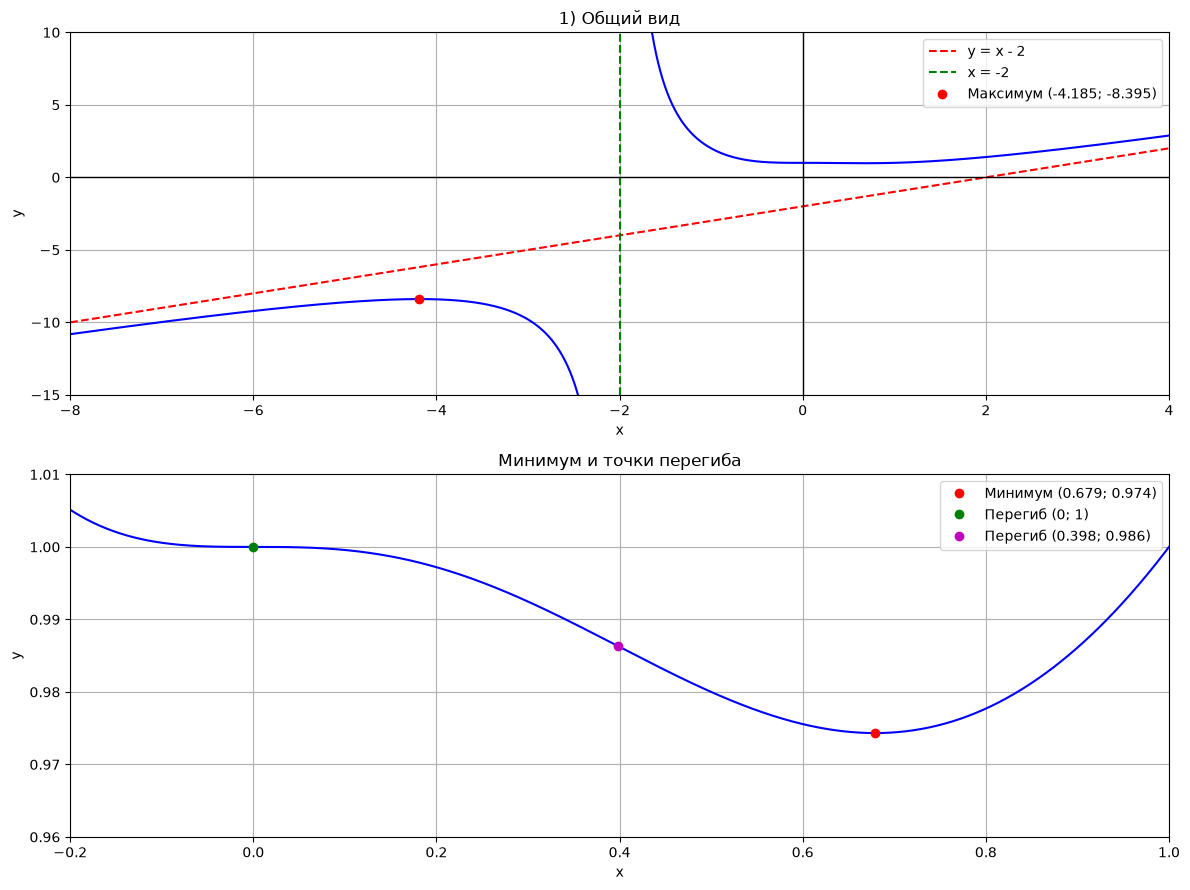

In [3]:
# 1)
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

t = sp.Symbol('t')
np.set_printoptions(precision=6, suppress=True)
F = (t**4 + 2*t**2 + t + 2)/(t**3 + 2*t**2 + t + 2)

d1 = sp.factor(sp.diff(F, t))
d2 = sp.factor(sp.diff(F, t, 2))

print('Первая производная:', d1)
print('Вторая производная:', d2)

def f(x):
    return (x**4 + 2*x**2 + x + 2)/(x**3 + 2*x**2 + x + 2)

df = sp.lambdify(t, d1, 'numpy')
ddf = sp.lambdify(t, d2, 'numpy')

xmax = optimize.brentq(df, -5, -4)
xmin = optimize.brentq(df, 0.6, 0.8)
xp1 = 0
xp2 = optimize.brentq(ddf, 0.3, 0.5)

print(f'Максимум: ({xmax:.6f}; {f(xmax):.6f})')
print(f'Минимум: ({xmin:.6f}; {f(xmin):.6f})')
print(f'Перегиб: ({xp1}; {f(xp1)})')
print(f'Перегиб: ({xp2:.6f}; {f(xp2):.6f})')

print('Предел слева от -2:', sp.limit(F, t, -2, dir='-'))
print('Предел справа от -2:', sp.limit(F, t, -2, dir='+'))

k1 = sp.limit(F/t, t, -sp.oo)
b1 = sp.limit(F - k1*t, t, -sp.oo)
k2 = sp.limit(F/t, t, sp.oo)
b2 = sp.limit(F - k2*t, t, sp.oo)

print(f'При x → -∞: k = {k1}, b = {b1}')
print(f'При x → +∞: k = {k2}, b = {b2}')

plt.figure(figsize=(12, 9))

# Общий вид графика
plt.subplot(2, 1, 1)

x1 = np.linspace(-8, -2.01, 1000)
x2 = np.linspace(-1.99, 4, 1000)

plt.plot(x1, f(x1), 'b')
plt.plot(x2, f(x2), 'b')

x = np.linspace(-8, 4, 1000)
plt.plot(x, x - 2, 'r--', label='y = x - 2')
plt.axvline(x=-2, color='green', linestyle='--', label='x = -2')
plt.plot(xmax, f(xmax), 'ro',
         label=f'Максимум ({xmax:.3f}; {f(xmax):.3f})')

plt.axhline(y=0, color='black', linewidth=1)
plt.axvline(x=0, color='black', linewidth=1)
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()
plt.title('1) Общий вид')
plt.xlim(-8, 4)
plt.ylim(-15, 10)

# Увеличенный участок
plt.subplot(2, 1, 2)

x = np.linspace(-0.2, 1, 1000)
plt.plot(x, f(x), 'b')

plt.plot(xmin, f(xmin), 'ro',
         label=f'Минимум ({xmin:.3f}; {f(xmin):.3f})')
plt.plot(xp1, f(xp1), 'go', label='Перегиб (0; 1)')
plt.plot(xp2, f(xp2), 'mo',
         label=f'Перегиб ({xp2:.3f}; {f(xp2):.3f})')

plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()
plt.title('Минимум и точки перегиба')
plt.xlim(-0.2, 1)
plt.ylim(0.96, 1.01)

plt.tight_layout()
plt.show()

Упражнение 2

Производная при x > 0: -sqrt(2)*t*(t**2 - 2)*exp(-t**2/2)/sqrt(pi)
Вторая производная при x > 0: sqrt(2)*(t**4 - 5*t**2 + 2)*exp(-t**2/2)/sqrt(pi)
Максимум: (1.414214; 0.587051)
Перегиб: (0.662153; 0.280963)
Перегиб: (2.135779; 0.371984)
Предел при x → +∞: 0


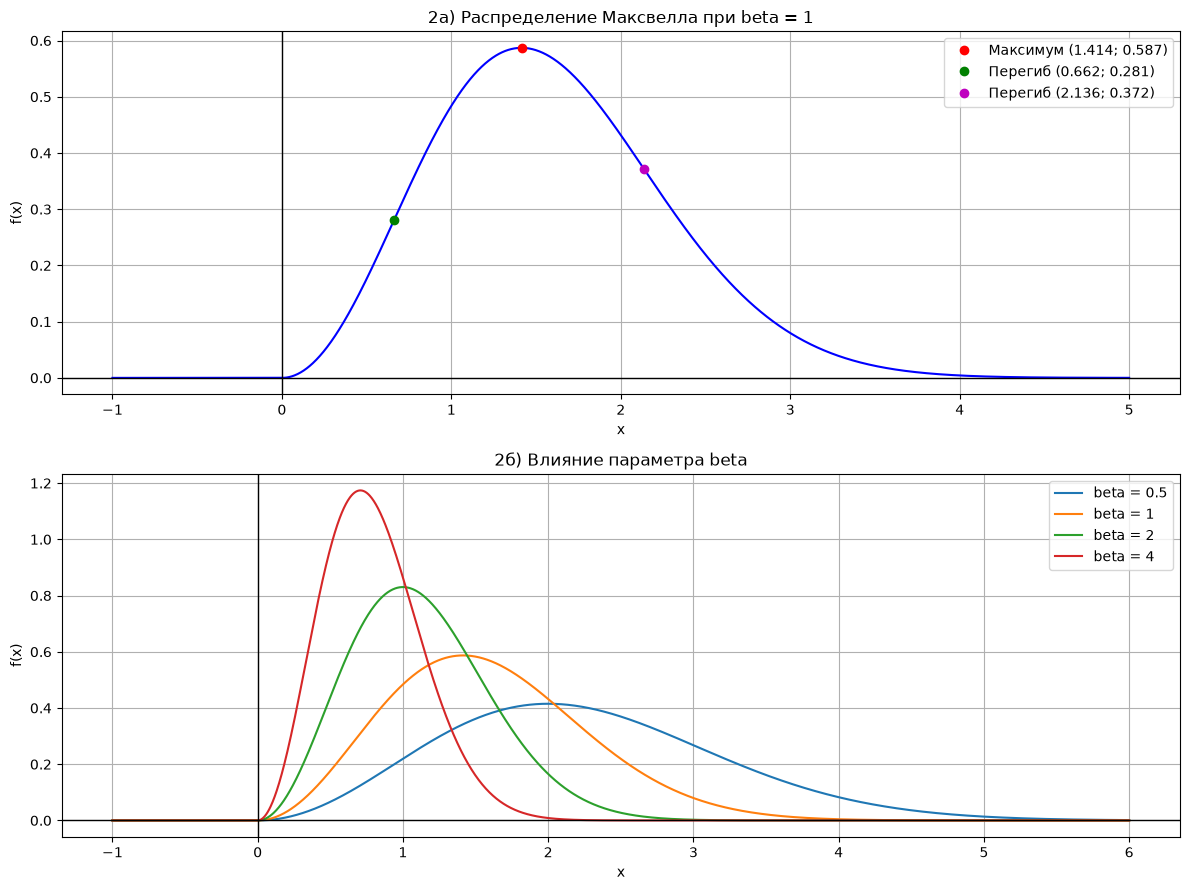

In [4]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

# 2)

F = sp.sqrt(2/sp.pi)*t**2*sp.exp(-t**2/2)

print('Производная при x > 0:', sp.factor(sp.diff(F, t)))
print('Вторая производная при x > 0:',
      sp.factor(sp.diff(F, t, 2)))

def f(x, beta):
    return np.where(
        x <= 0,
        0,
        np.sqrt(2/np.pi)*beta**1.5*x**2*np.exp(-beta*x**2/2)
    )

xmax = np.sqrt(2)
xp1 = np.sqrt((5 - np.sqrt(17))/2)
xp2 = np.sqrt((5 + np.sqrt(17))/2)

print(f'Максимум: ({xmax:.6f}; {f(xmax, 1):.6f})')
print(f'Перегиб: ({xp1:.6f}; {f(xp1, 1):.6f})')
print(f'Перегиб: ({xp2:.6f}; {f(xp2, 1):.6f})')
print('Предел при x → +∞:', sp.limit(F, t, sp.oo))

plt.figure(figsize=(12, 9))

# а) beta = 1
plt.subplot(2, 1, 1)

x = np.linspace(-1, 5, 2000)
plt.plot(x, f(x, 1), 'b')

plt.plot(xmax, f(xmax, 1), 'ro',
         label=f'Максимум ({xmax:.3f}; {f(xmax, 1):.3f})')
plt.plot(xp1, f(xp1, 1), 'go',
         label=f'Перегиб ({xp1:.3f}; {f(xp1, 1):.3f})')
plt.plot(xp2, f(xp2, 1), 'mo',
         label=f'Перегиб ({xp2:.3f}; {f(xp2, 1):.3f})')

plt.axhline(y=0, color='black', linewidth=1)
plt.axvline(x=0, color='black', linewidth=1)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid()
plt.legend()
plt.title('2а) Распределение Максвелла при beta = 1')

# б) Влияние параметра
plt.subplot(2, 1, 2)

x = np.linspace(-1, 6, 2000)

plt.plot(x, f(x, 0.5), label='beta = 0.5')
plt.plot(x, f(x, 1), label='beta = 1')
plt.plot(x, f(x, 2), label='beta = 2')
plt.plot(x, f(x, 4), label='beta = 4')

plt.axhline(y=0, color='black', linewidth=1)
plt.axvline(x=0, color='black', linewidth=1)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid()
plt.legend()
plt.title('2б) Влияние параметра beta')

plt.tight_layout()
plt.show()

Упражнение 3

Первая производная: sqrt(t**2*(t - 2)/(t - 3))*(t - 4)*(2*t - 3)/(2*t*(t - 3)*(t - 2))
Вторая производная: sqrt(t**2*(t - 2)/(t - 3))*(11*t - 24)/(4*t*(t - 3)**2*(t - 2)**2)
Предел справа от 3: oo
Максимум: (1.500000; 0.866025)
Минимум: (4.000000; 5.656854)
Другие минимумы: (0; 0), (2; 0)
Асимптоты: x = 3, y = -x - 0.5, y = x + 0.5


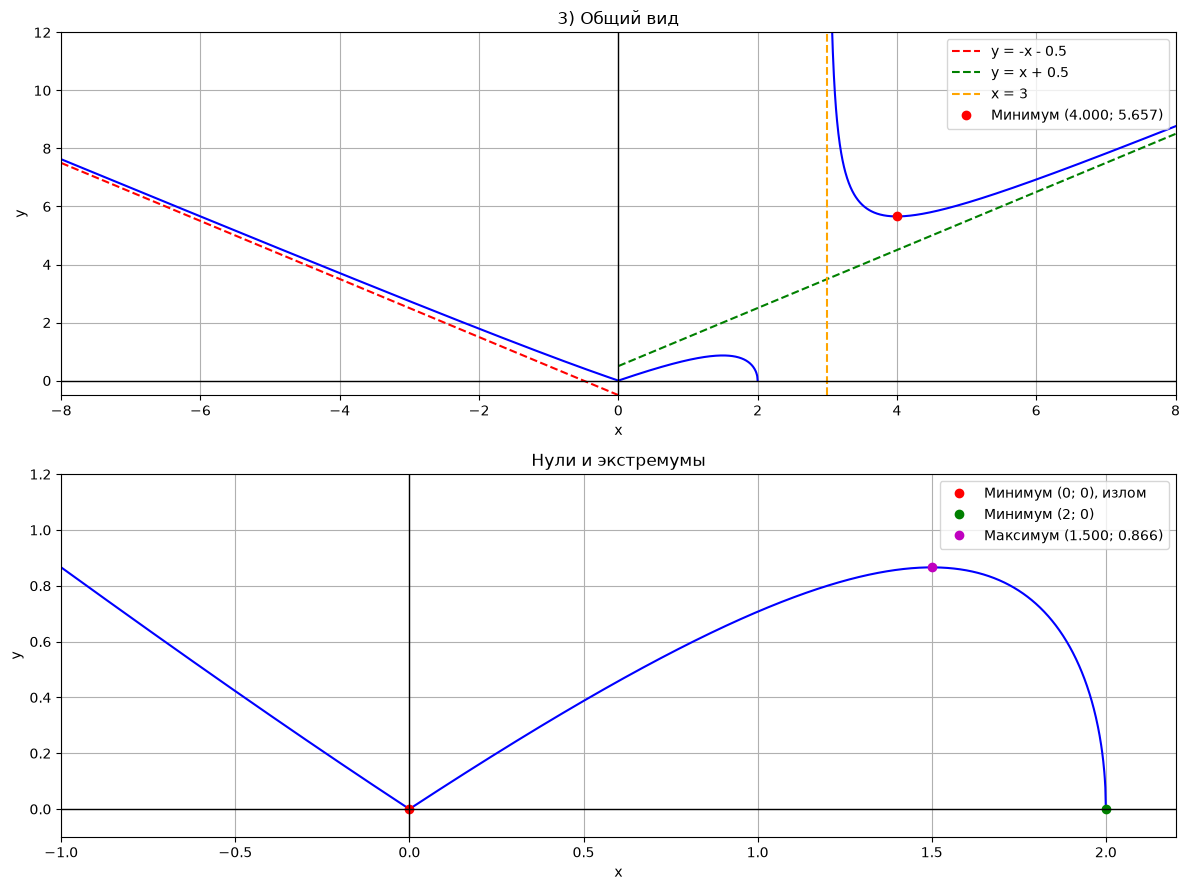

In [5]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

# 3)

F = sp.sqrt((t**3 - 2*t**2)/(t - 3))

print('Первая производная:', sp.factor(sp.diff(F, t)))
print('Вторая производная:', sp.factor(sp.diff(F, t, 2)))
print('Предел справа от 3:', sp.limit(F, t, 3, dir='+'))

def f(x):
    return np.sqrt((x**3 - 2*x**2)/(x - 3))

def df(x):
    return x*(2*x - 3)*(x - 4)/(2*(x - 3)**2*f(x))

xmax = optimize.brentq(df, 1, 1.9)
xmin = optimize.brentq(df, 3.1, 5)

print(f'Максимум: ({xmax:.6f}; {f(xmax):.6f})')
print(f'Минимум: ({xmin:.6f}; {f(xmin):.6f})')
print('Другие минимумы: (0; 0), (2; 0)')
print('Асимптоты: x = 3, y = -x - 0.5, y = x + 0.5')

plt.figure(figsize=(12, 9))

# Общий вид
plt.subplot(2, 1, 1)

x1 = np.linspace(-8, 2, 2000)
x2 = np.linspace(3.01, 8, 1000)

plt.plot(x1, f(x1), 'b')
plt.plot(x2, f(x2), 'b')

x1 = np.linspace(-8, 0, 1000)
x2 = np.linspace(0, 8, 1000)

plt.plot(x1, -x1 - 0.5, 'r--', label='y = -x - 0.5')
plt.plot(x2, x2 + 0.5, 'g--', label='y = x + 0.5')
plt.axvline(x=3, color='orange', linestyle='--', label='x = 3')

plt.plot(xmin, f(xmin), 'ro',
         label=f'Минимум ({xmin:.3f}; {f(xmin):.3f})')

plt.axhline(y=0, color='black', linewidth=1)
plt.axvline(x=0, color='black', linewidth=1)
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()
plt.title('3) Общий вид')
plt.xlim(-8, 8)
plt.ylim(-0.5, 12)

# Увеличенный участок
plt.subplot(2, 1, 2)

x = np.linspace(-1, 2, 2000)
plt.plot(x, f(x), 'b')

plt.plot(0, 0, 'ro', label='Минимум (0; 0), излом')
plt.plot(2, 0, 'go', label='Минимум (2; 0)')
plt.plot(xmax, f(xmax), 'mo',
         label=f'Максимум ({xmax:.3f}; {f(xmax):.3f})')

plt.axhline(y=0, color='black', linewidth=1)
plt.axvline(x=0, color='black', linewidth=1)
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()
plt.title('Нули и экстремумы')
plt.xlim(-1, 2.2)
plt.ylim(-0.1, 1.2)

plt.tight_layout()
plt.show()

Упражнение 4

Максимумы: столбцы x и f(x)
[[0.155451 0.851251]
 [0.822117 0.437047]
 [1.488784 0.224387]]
Минимумы: столбцы x и f(x)
[[ 0.488784 -0.609948]
 [ 1.155451 -0.313158]
 [ 1.822117 -0.160781]]


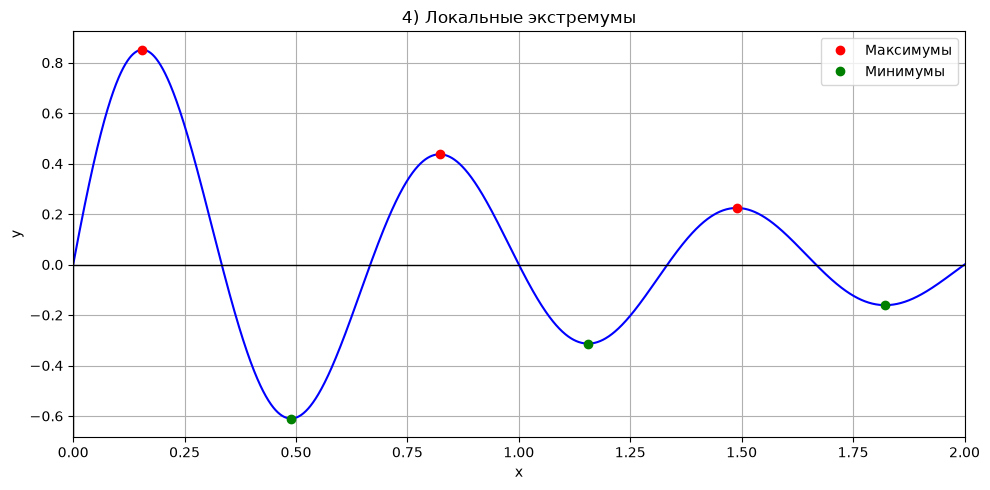

In [6]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

# 4)

def f(x):
    return np.exp(-x)*np.sin(3*np.pi*x)

def minus_f(x):
    return -f(x)

max1 = optimize.fmin(minus_f, 0.15, xtol=1e-10, disp=False)[0]
max2 = optimize.fmin(minus_f, 0.82, xtol=1e-10, disp=False)[0]
max3 = optimize.fmin(minus_f, 1.49, xtol=1e-10, disp=False)[0]

min1 = optimize.fmin(f, 0.49, xtol=1e-10, disp=False)[0]
min2 = optimize.fmin(f, 1.16, xtol=1e-10, disp=False)[0]
min3 = optimize.fmin(f, 1.82, xtol=1e-10, disp=False)[0]

xmax = np.array([max1, max2, max3])
xmin = np.array([min1, min2, min3])

print('Максимумы: столбцы x и f(x)')
print(np.column_stack((xmax, f(xmax))))

print('Минимумы: столбцы x и f(x)')
print(np.column_stack((xmin, f(xmin))))

x = np.linspace(0, 2, 2000)

plt.figure(figsize=(10, 5))
plt.plot(x, f(x), 'b')
plt.plot(xmax, f(xmax), 'ro', label='Максимумы')
plt.plot(xmin, f(xmin), 'go', label='Минимумы')

plt.axhline(y=0, color='black', linewidth=1)
plt.axvline(x=0, color='black', linewidth=1)
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()
plt.title('4) Локальные экстремумы')
plt.xlim(0, 2)

plt.tight_layout()
plt.show()

Первая производная: t**2*sin(t) - 2*t*cos(t) + cos(t)
Вторая производная: t**2*cos(t) + 4*t*sin(t) - sin(t) - 2*cos(t)
Точки перегиба: столбцы x и f(x)
[[ -8.325277  30.578728]
 [ -5.405776 -17.908307]
 [ -2.716071   6.306383]
 [ -0.515408  -0.724026]
 [  0.699219   0.269437]
 [  2.657589   6.716867]
 [  5.364758 -18.266517]
 [  8.302507  30.792416]]
Знаки второй производной слева:
[-1.  1. -1.  1. -1.  1. -1.  1.]
Знаки второй производной справа:
[ 1. -1.  1. -1.  1. -1.  1. -1.]


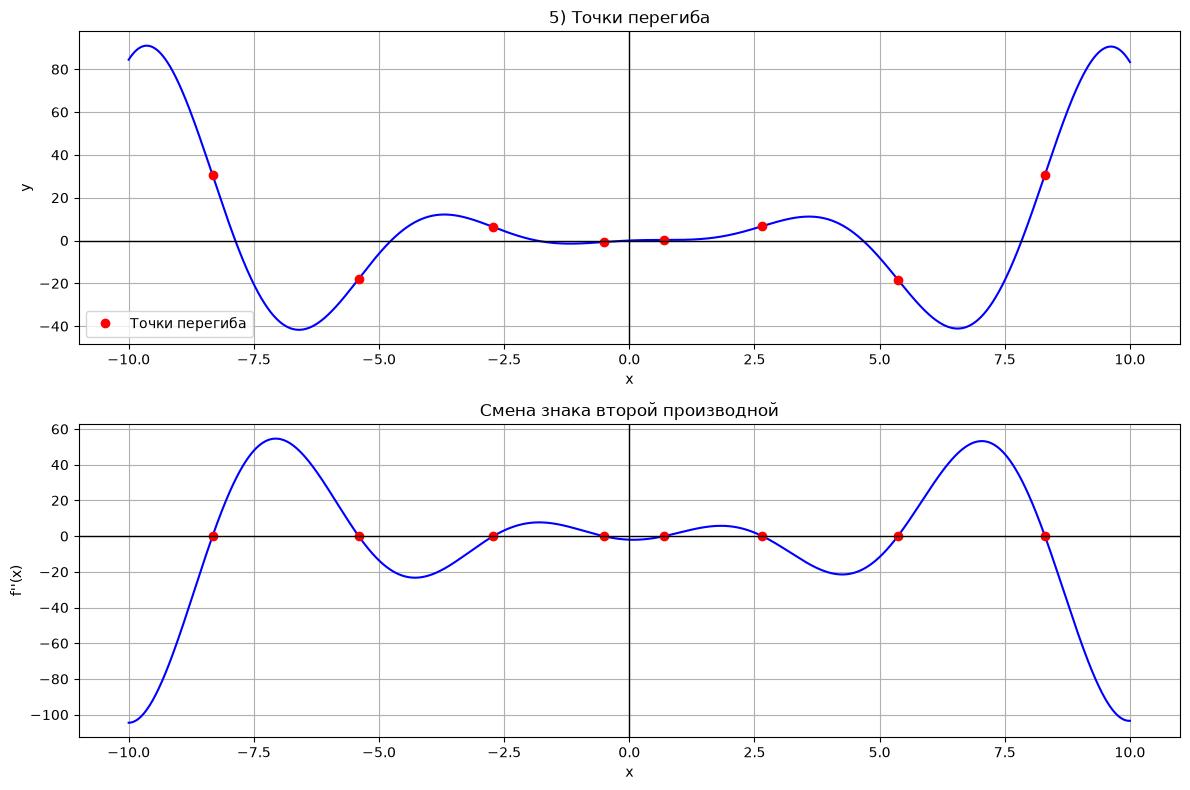

In [7]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

# 5)

F = sp.sin(t) - t**2*sp.cos(t)

print('Первая производная:', sp.diff(F, t))
print('Вторая производная:', sp.expand(sp.diff(F, t, 2)))

def f(x):
    return np.sin(x) - x**2*np.cos(x)

def ddf(x):
    return (x**2 - 2)*np.cos(x) + (4*x - 1)*np.sin(x)

xp1 = optimize.brentq(ddf, -8.4, -8.3)
xp2 = optimize.brentq(ddf, -5.5, -5.4)
xp3 = optimize.brentq(ddf, -2.8, -2.7)
xp4 = optimize.brentq(ddf, -0.6, -0.5)
xp5 = optimize.brentq(ddf, 0.6, 0.7)
xp6 = optimize.brentq(ddf, 2.6, 2.7)
xp7 = optimize.brentq(ddf, 5.3, 5.4)
xp8 = optimize.brentq(ddf, 8.3, 8.4)

xp = np.array([xp1, xp2, xp3, xp4, xp5, xp6, xp7, xp8])

print('Точки перегиба: столбцы x и f(x)')
print(np.column_stack((xp, f(xp))))

print('Знаки второй производной слева:')
print(np.sign(ddf(xp - 0.001)))

print('Знаки второй производной справа:')
print(np.sign(ddf(xp + 0.001)))

plt.figure(figsize=(12, 8))

plt.subplot(2, 1, 1)

x = np.linspace(-10, 10, 4000)
plt.plot(x, f(x), 'b')
plt.plot(xp, f(xp), 'ro', label='Точки перегиба')

plt.axhline(y=0, color='black', linewidth=1)
plt.axvline(x=0, color='black', linewidth=1)
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()
plt.title('5) Точки перегиба')

plt.subplot(2, 1, 2)

plt.plot(x, ddf(x), 'b')
plt.plot(xp, np.zeros_like(xp), 'ro')

plt.axhline(y=0, color='black', linewidth=1)
plt.axvline(x=0, color='black', linewidth=1)
plt.xlabel('x')
plt.ylabel("f''(x)")
plt.grid()
plt.title('Смена знака второй производной')

plt.tight_layout()
plt.show()

Первая производная: -2*t*exp(1/(t**2 - 1))/((t - 1)**2*(t + 1)**2)
Вторая производная: 2*(3*t**4 - 1)*exp(1/(t**2 - 1))/((t - 1)**4*(t + 1)**4)
Максимум: (0; 0.367879)
Перегиб: (-0.759836; 0.093853)
Перегиб: (0.759836; 0.093853)
tg(alpha) в левом перегибе: 0.798430
tg(alpha) в правом перегибе: -0.798430
Левая касательная: y = 0.798430*x + 0.700528
Правая касательная: y = -0.798430*x + 0.700528
Предел слева от -1: oo
Предел справа от -1: 0
Предел слева от 1: 0
Предел справа от 1: oo
Предел при x → -∞: 1
Предел при x → +∞: 1


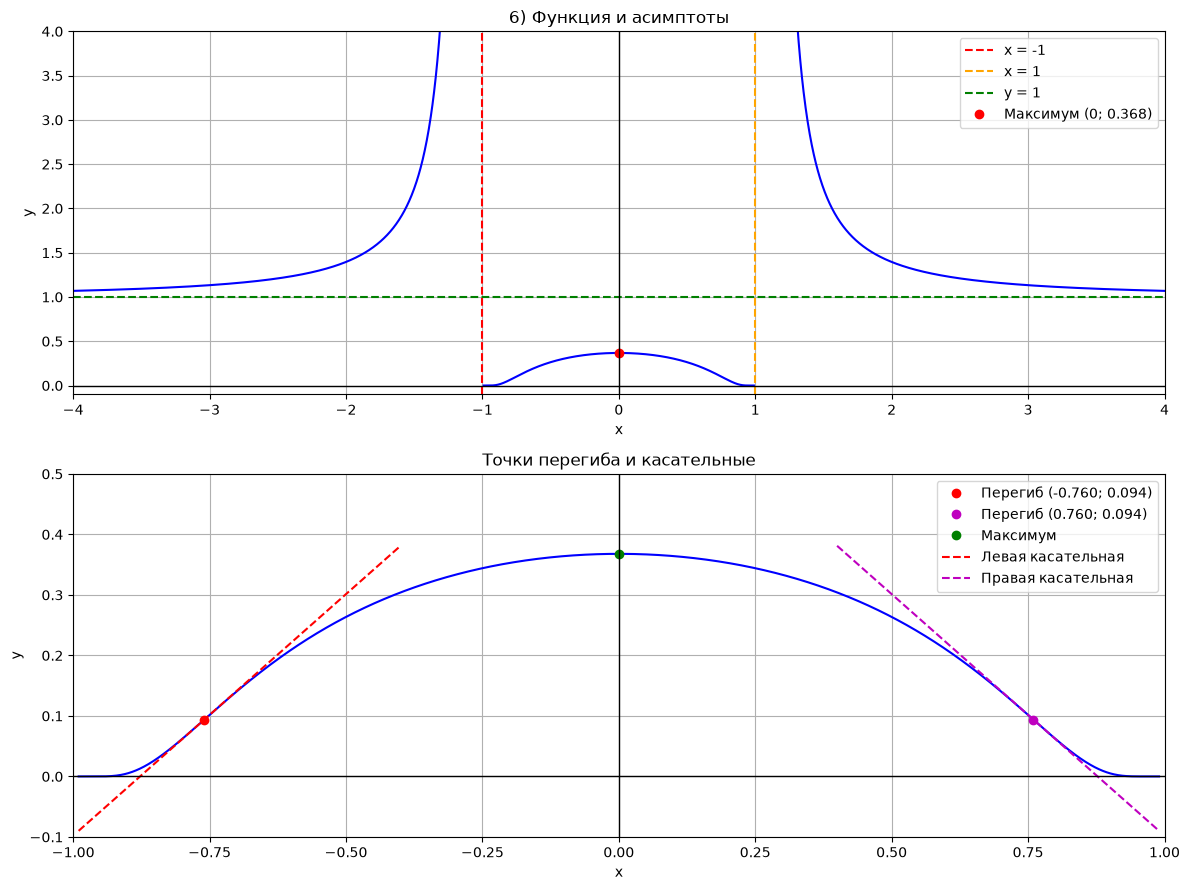

In [8]:
# 1)
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

# 6)

F = sp.exp(1/(t**2 - 1))

d1 = sp.factor(sp.diff(F, t))
d2 = sp.factor(sp.diff(F, t, 2))

print('Первая производная:', d1)
print('Вторая производная:', d2)

def f(x):
    return np.exp(1/(x**2 - 1))

def df(x):
    return -2*x*np.exp(1/(x**2 - 1))/(x**2 - 1)**2

xp1 = -3**(-1/4)
xp2 = 3**(-1/4)

yp1 = f(xp1)
yp2 = f(xp2)

# Тангенсы углов наклона касательных
k1 = df(xp1)
k2 = df(xp2)

print(f'Максимум: (0; {f(0):.6f})')
print(f'Перегиб: ({xp1:.6f}; {yp1:.6f})')
print(f'Перегиб: ({xp2:.6f}; {yp2:.6f})')

print(f'tg(alpha) в левом перегибе: {k1:.6f}')
print(f'tg(alpha) в правом перегибе: {k2:.6f}')

print(f'Левая касательная: y = {k1:.6f}*x + {yp1-k1*xp1:.6f}')
print(f'Правая касательная: y = {k2:.6f}*x + {yp2-k2*xp2:.6f}')

print('Предел слева от -1:', sp.limit(F, t, -1, dir='-'))
print('Предел справа от -1:', sp.limit(F, t, -1, dir='+'))
print('Предел слева от 1:', sp.limit(F, t, 1, dir='-'))
print('Предел справа от 1:', sp.limit(F, t, 1, dir='+'))

print('Предел при x → -∞:', sp.limit(F, t, -sp.oo))
print('Предел при x → +∞:', sp.limit(F, t, sp.oo))

plt.figure(figsize=(12, 9))

# Общий вид
plt.subplot(2, 1, 1)

x1 = np.linspace(-4, -1.01, 1000)
x2 = np.linspace(-0.99, 0.99, 2000)
x3 = np.linspace(1.01, 4, 1000)

plt.plot(x1, f(x1), 'b')
plt.plot(x2, f(x2), 'b')
plt.plot(x3, f(x3), 'b')

plt.axvline(x=-1, color='red', linestyle='--', label='x = -1')
plt.axvline(x=1, color='orange', linestyle='--', label='x = 1')
plt.axhline(y=1, color='green', linestyle='--', label='y = 1')

plt.plot(0, f(0), 'ro', label=f'Максимум (0; {f(0):.3f})')

plt.axhline(y=0, color='black', linewidth=1)
plt.axvline(x=0, color='black', linewidth=1)
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()
plt.title('6) Функция и асимптоты')
plt.xlim(-4, 4)
plt.ylim(-0.1, 4)

# Перегибы и касательные
plt.subplot(2, 1, 2)

x = np.linspace(-0.99, 0.99, 2000)
plt.plot(x, f(x), 'b')

plt.plot(xp1, yp1, 'ro',
         label=f'Перегиб ({xp1:.3f}; {yp1:.3f})')
plt.plot(xp2, yp2, 'mo',
         label=f'Перегиб ({xp2:.3f}; {yp2:.3f})')
plt.plot(0, f(0), 'go', label='Максимум')

# Касательная: y = f(x0) + f'(x0)*(x - x0)
x1 = np.linspace(-0.99, -0.4, 1000)
x2 = np.linspace(0.4, 0.99, 1000)

y1 = yp1 + k1*(x1 - xp1)
y2 = yp2 + k2*(x2 - xp2)

plt.plot(x1, y1, 'r--', label='Левая касательная')
plt.plot(x2, y2, 'm--', label='Правая касательная')

plt.axhline(y=0, color='black', linewidth=1)
plt.axvline(x=0, color='black', linewidth=1)
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()
plt.title('Точки перегиба и касательные')
plt.xlim(-1, 1)
plt.ylim(-0.1, 0.5)

plt.tight_layout()
plt.show()